# Stage 7: Brønsted analysis for pyridine nucleophiles

This notebook correlates the final $k_{2,\mathrm{high}}$ values for pyridine nucleophiles with $\mathrm{p}K_\mathrm{a}$ and determines $\beta_\mathrm{nuc}$ for P5–P9.

Place `stage6_k2_high_selection_summary.xlsx` and `nucleophile_pka.xlsx` beside the notebook. All results are written directly to `bronsted_analysis/`.

In [1]:
"""Configuration, plotting style and shared constants."""
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore", category=RuntimeWarning)

# --- Paths -------------------------------------------------------------------
NOTEBOOK_DIR = Path.cwd().resolve()
SUMMARY_XLSX = NOTEBOOK_DIR / "stage6_k2_high_selection_summary.xlsx"
NUCLEOPHILE_PKA_XLSX = NOTEBOOK_DIR / "nucleophile_pka.xlsx"
OUTPUT_DIR = NOTEBOOK_DIR / "bronsted_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Analysis settings -------------------------------------------------------
MAX_LOG_CI_WIDTH = 3.0        # Maximum accepted width of the k2,high 95% CI in lg units
BOOTSTRAP_N = 2000            # Bayesian (Dirichlet-weight) bootstrap replicates
RANDOM_SEED = 20260709         # Seed for reproducible bootstrap confidence intervals
OUTLIER_MIN_INLIERS = 3       # never fit a line to fewer points than this
OUTLIER_MAD_FACTOR = 4.0      # residual cut-off in robust (MAD) sigma
OUTLIER_COOKS_D_FACTOR = 8.0  # Cook's distance cut-off is this factor / n

# --- Figure style ------------------------------------------------------------
PX_ORDER = ["P7", "P8", "P9", "P5", "P6"]
PX_COLORS = {
    "P7": "#20385f",  # DMAPP
    "P8": "#4f7fa3",  # MPP
    "P9": "#98dadd",  # AzaP
    "P5": "#e43f45",  # DNPP
    "P6": "#ef8e94",  # PCPP
}
BASE_FONT_SIZE = 14
FIG_DPI = 300

# Axis labels: k italic, "2,high" upright subscript, p and a upright in pKa.
LABEL_LG_K2 = r"$\lg\,k_{2,\mathrm{high}}$"
LABEL_PKA = r"$\mathrm{p}K_\mathrm{a}$"

plt.rcParams.update({
    "font.family": "Arial",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    # Render maths in Arial too, so k_{2,high} matches the surrounding text.
    "mathtext.fontset": "custom",
    "mathtext.rm": "Arial",
    "mathtext.it": "Arial:italic",
    "mathtext.bf": "Arial:bold",
    "axes.linewidth": 1.25,
    "font.size": BASE_FONT_SIZE,
    "axes.labelsize": BASE_FONT_SIZE,
    "xtick.labelsize": BASE_FONT_SIZE,
    "ytick.labelsize": BASE_FONT_SIZE,
    "legend.fontsize": BASE_FONT_SIZE,
    "savefig.bbox": "tight",
    "figure.dpi": FIG_DPI,
})
pd.set_option("display.float_format", "{:.3g}".format)

rng = np.random.default_rng(RANDOM_SEED)
SAVED_FILES = []


def save_figure(fig, filename):
    """Save a figure into OUTPUT_DIR and record the path for the final listing."""
    path = OUTPUT_DIR / filename
    fig.savefig(path)
    SAVED_FILES.append(path)
    return path


for path in (SUMMARY_XLSX, NUCLEOPHILE_PKA_XLSX):
    if not path.is_file():
        raise FileNotFoundError(f"Could not find {path.name}. Place it beside this notebook.")
print(f"SUMMARY_XLSX = {SUMMARY_XLSX}")
print(f"NUCLEOPHILE_PKA_XLSX = {NUCLEOPHILE_PKA_XLSX}")
print(f"OUTPUT_DIR = {OUTPUT_DIR}")

SUMMARY_XLSX = /Users/robertmayer/Desktop/mayerlab_local/phosphorylation_publ/section5_6_kinetics/stage6_k2_high_selection_summary.xlsx
NUCLEOPHILE_PKA_XLSX = /Users/robertmayer/Desktop/mayerlab_local/phosphorylation_publ/section5_6_kinetics/nucleophile_pka.xlsx
OUTPUT_DIR = /Users/robertmayer/Desktop/mayerlab_local/phosphorylation_publ/section5_6_kinetics/bronsted_analysis


## 1 · Data

The Stage 6 summary is matched to the reference table by `Nu` identifier. Nu2–Nu11 are retained; values with a 95 % confidence interval wider than `MAX_LOG_CI_WIDTH` logarithmic units are excluded. Values without confidence limits remain eligible but are plotted without error bars.

In [2]:
"""Load and validate the Stage 6 summary and the nucleophile pKa table."""

PYRIDINE_IDS = [f"Nu{i}" for i in range(2, 12)]
SUMMARY_REQUIRED = {
    "PX", "nu_id", "nu_name", "final_k2_high",
    "final_k2_high_lo95", "final_k2_high_hi95", "final_k2_high_method",
}
REFERENCE_REQUIRED = {"Nu_ID", "Nucleophile name", "pKa", "Reference for pKa"}

summary = pd.read_excel(SUMMARY_XLSX, sheet_name="summary")
missing_summary_cols = SUMMARY_REQUIRED - set(summary.columns)
if missing_summary_cols:
    raise ValueError(f"{SUMMARY_XLSX.name} is missing required columns: {sorted(missing_summary_cols)}")
summary["nu_id"] = summary["nu_id"].astype(str).str.strip()
summary["nu_name"] = summary["nu_name"].astype(str).str.strip()

nu_ref = pd.read_excel(NUCLEOPHILE_PKA_XLSX)
missing_reference_cols = REFERENCE_REQUIRED - set(nu_ref.columns)
if missing_reference_cols:
    raise ValueError(f"{NUCLEOPHILE_PKA_XLSX.name} is missing required columns: {sorted(missing_reference_cols)}")
nu_ref = nu_ref.rename(columns={
    "Nu_ID": "nu_id",
    "Nucleophile name": "nu_name_reference",
    "pKa": "nu_pKa",
    "Reference for pKa": "nu_pKa_reference",
})
nu_ref["nu_id"] = nu_ref["nu_id"].astype(str).str.strip()
nu_ref["nu_name_reference"] = nu_ref["nu_name_reference"].astype(str).str.strip()
nu_ref["nu_pKa"] = pd.to_numeric(nu_ref["nu_pKa"], errors="coerce")
pyridine_ref = nu_ref[nu_ref["nu_id"].isin(PYRIDINE_IDS)].copy()

missing_ids = sorted(set(PYRIDINE_IDS) - set(pyridine_ref["nu_id"]))
if missing_ids:
    raise ValueError(f"Missing pyridine reference entries: {missing_ids}")
if pyridine_ref["nu_id"].duplicated().any():
    duplicates = sorted(pyridine_ref.loc[pyridine_ref["nu_id"].duplicated(False), "nu_id"].unique())
    raise ValueError(f"Duplicate pyridine reference entries: {duplicates}")

pyridine_summary = summary[summary["nu_id"].isin(PYRIDINE_IDS)].copy()
name_check = pyridine_summary[["nu_id", "nu_name"]].drop_duplicates().merge(
    pyridine_ref[["nu_id", "nu_name_reference"]], on="nu_id", how="left"
)
name_mismatches = name_check[name_check["nu_name"] != name_check["nu_name_reference"]]
if len(name_mismatches):
    raise ValueError("Nucleophile names do not match nucleophile_pka.xlsx:\n" + name_mismatches.to_string(index=False))


def drop_unconstrained_k2(df):
    """Discard k2,high values whose 95% CI spans more than MAX_LOG_CI_WIDTH orders of magnitude.

    Stage 6 selects fitted values using the relative CI width (hi - lo) / k2,high.
    When the lower confidence limit collapses towards zero that expression reduces to
    hi / k2,high and stays small, so a value that the fit never constrained from below
    still passes. Such values carry no information and must not enter a correlation.
    Rows without usable confidence limits are kept, since the width cannot be evaluated.
    """
    lo = pd.to_numeric(df["final_k2_high_lo95"], errors="coerce")
    hi = pd.to_numeric(df["final_k2_high_hi95"], errors="coerce")
    width = np.log10(hi.where(hi > 0)) - np.log10(lo.where(lo > 0))
    drop = width > MAX_LOG_CI_WIDTH
    dropped = df.loc[drop, ["PX", "nu_id", "nu_name", "final_k2_high",
                            "final_k2_high_lo95", "final_k2_high_hi95",
                            "final_k2_high_method"]].assign(log_ci_width=width[drop])
    return df[~drop].copy(), dropped


pyridine_summary, unconstrained = drop_unconstrained_k2(pyridine_summary)

print(f"Stage 6 summary rows: {len(summary)}  ({summary['PX'].nunique()} agents, "
      f"{summary['nu_id'].nunique()} nucleophiles)")
print(f"Pyridine rows retained for analysis: {len(pyridine_summary)}")
print(f"discarded as unconstrained (95% CI > {MAX_LOG_CI_WIDTH:g} orders of magnitude): "
      f"{len(unconstrained)}")
if len(unconstrained):
    display(unconstrained.sort_values("log_ci_width", ascending=False).reset_index(drop=True))
print("pyridine reference set:")
display(
    pyridine_ref[["nu_id", "nu_name_reference", "nu_pKa"]]
    .sort_values("nu_pKa")
    .reset_index(drop=True)
)

Stage 6 summary rows: 137  (5 agents, 29 nucleophiles)
Pyridine rows retained for analysis: 46
discarded as unconstrained (95% CI > 3 orders of magnitude): 3


,PX,nu_id,nu_name,final_k2_high,final_k2_high_lo95,final_k2_high_hi95,final_k2_high_method,log_ci_width
0,P9,Nu7,3-methoxypyridine,1.83e-05,2.88e-22,4.56e-05,B_global,17.2
1,P5,Nu11,4-morpholinopyridine,6.08e-06,4.27e-21,1.29e-05,B_global,15.5
2,P6,Nu7,3-methoxypyridine,3.04e-06,3.38e-20,6e-06,B_global,14.2


pyridine reference set:


,nu_id,nu_name_reference,nu_pKa
0,Nu9,3-cyanopyridine,1.35
1,Nu10,4-cyanopyridine,1.86
2,Nu7,3-methoxypyridine,4.91
3,Nu2,pyridine,5.23
4,Nu3,3-methylpyridine,5.67
5,Nu4,4-methylpyridine,5.98
6,Nu6,4-ethylpyridine,6.03
7,Nu8,4-methoxypyridine,6.47
8,Nu5,"3,4-lutidine",6.48
9,Nu11,4-morpholinopyridine,8.53


## 2 · Brønsted plots

For each phosphorylating agent, $\lg k_{2,\mathrm{high}}$ is fitted against $\mathrm{p}K_\mathrm{a}$ by ordinary least squares. Influential points identified by the MAD-residual and Cook's-distance criteria are shown faded and excluded from the fit. Bayesian bootstrapping provides the 95 % confidence bands.

Plots are generated for P5–P9 and for the P5/P7/P8 subset.

In [3]:
"""Fitting, outlier diagnostics and the Brønsted data builder."""


def fit_line(x, y):
    """Ordinary least-squares line; returns (slope, intercept, r2)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 2:
        return np.nan, np.nan, np.nan
    slope, intercept = np.polyfit(x[mask], y[mask], 1)
    resid = y[mask] - (slope * x[mask] + intercept)
    ss_tot = np.sum((y[mask] - np.mean(y[mask])) ** 2)
    r2 = np.nan if ss_tot == 0 else 1 - np.sum(resid ** 2) / ss_tot
    return slope, intercept, r2


def bayesian_bootstrap_line(x, y, n_boot=BOOTSTRAP_N):
    """Dirichlet-weighted bootstrap of the linear fit."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    if len(x) < 2:
        return pd.DataFrame(columns=["slope_beta_nuc", "intercept"])

    X = np.column_stack([x, np.ones_like(x)])
    rows = []
    for _ in range(n_boot):
        w = np.sqrt(rng.dirichlet(np.ones(len(x))) * len(x))[:, None]
        try:
            slope, intercept = np.linalg.lstsq(X * w, y * w[:, 0], rcond=None)[0]
        except np.linalg.LinAlgError:
            continue
        rows.append({"slope_beta_nuc": slope, "intercept": intercept})
    return pd.DataFrame(rows)


def linear_outlier_diagnostics(group):
    """Flag influential Brønsted points by residual MAD and Cook's distance."""
    x = group["nu_pKa"].to_numpy(float)
    y = group["lg_k2_high"].to_numpy(float)
    n = len(group)

    out = pd.DataFrame(index=group.index)
    out["bronsted_inlier"] = True
    out["bronsted_residual"] = np.nan
    out["bronsted_leverage"] = np.nan
    out["bronsted_cooks_d"] = np.nan
    out["bronsted_outlier_reason"] = ""
    out["bronsted_cooks_d_cutoff"] = OUTLIER_COOKS_D_FACTOR / n if n else np.nan
    if n < OUTLIER_MIN_INLIERS + 1:
        return out

    X = np.column_stack([np.ones_like(x), x])
    try:
        beta = np.linalg.lstsq(X, y, rcond=None)[0]
        resid = y - X @ beta
        leverage = np.diag(X @ np.linalg.inv(X.T @ X) @ X.T)
    except np.linalg.LinAlgError:
        return out

    p = X.shape[1]
    mse = np.sum(resid ** 2) / max(n - p, 1)
    cooks = np.zeros_like(resid)
    if np.isfinite(mse) and mse > 0:
        cooks = (resid ** 2 / (p * mse)) * (leverage / np.maximum((1 - leverage) ** 2, 1e-12))

    resid_median = np.nanmedian(resid)
    mad = np.nanmedian(np.abs(resid - resid_median))
    resid_scale = 1.4826 * mad if np.isfinite(mad) and mad > 0 else np.nanstd(resid)
    if not np.isfinite(resid_scale) or resid_scale == 0:
        resid_scale = np.inf

    residual_outlier = np.abs(resid - resid_median) > OUTLIER_MAD_FACTOR * resid_scale
    cooks_cutoff = OUTLIER_COOKS_D_FACTOR / n
    influence_outlier = cooks > cooks_cutoff
    proposed = residual_outlier | influence_outlier

    # Never discard so many points that a correlation cannot be fitted.
    if n - proposed.sum() < OUTLIER_MIN_INLIERS:
        scores = np.maximum(
            np.abs(resid - resid_median) / resid_scale if np.isfinite(resid_scale) else np.zeros_like(resid),
            cooks / cooks_cutoff if cooks_cutoff > 0 else np.zeros_like(cooks),
        )
        limited = np.zeros_like(proposed, dtype=bool)
        for idx in np.argsort(scores)[::-1][:max(n - OUTLIER_MIN_INLIERS, 0)]:
            if proposed[idx]:
                limited[idx] = True
        proposed = limited

    reasons = [
        "; ".join(r for r, flag in (("MAD residual", a), ("Cook's distance", b)) if flag)
        for a, b in zip(residual_outlier, influence_outlier)
    ]
    out["bronsted_inlier"] = ~proposed
    out["bronsted_residual"] = resid
    out["bronsted_leverage"] = leverage
    out["bronsted_cooks_d"] = cooks
    out["bronsted_outlier_reason"] = np.where(proposed, reasons, "")
    return out


def build_bronsted_data(summary_df):
    """Merge the summary with the pyridine reference set; add lg values and diagnostics."""
    data = summary_df.merge(
        pyridine_ref[["nu_id", "nu_name_reference", "nu_pKa", "nu_pKa_reference"]],
        on="nu_id", how="inner", validate="many_to_one",
    )
    for col in ["final_k2_high", "final_k2_high_lo95", "final_k2_high_hi95", "nu_pKa"]:
        data[col] = pd.to_numeric(data[col], errors="coerce")
    data = data[
        np.isfinite(data["final_k2_high"])
        & (data["final_k2_high"] > 0)
        & np.isfinite(data["nu_pKa"])
    ].copy()

    data["lg_k2_high"] = np.log10(data["final_k2_high"])
    for bound in ("lo95", "hi95"):
        values = data[f"final_k2_high_{bound}"]
        data[f"lg_k2_high_{bound}"] = np.where(
            np.isfinite(values) & (values > 0), np.log10(values.where(values > 0)), np.nan
        )
    data["lg_err_low"] = data["lg_k2_high"] - data["lg_k2_high_lo95"]
    data["lg_err_high"] = data["lg_k2_high_hi95"] - data["lg_k2_high"]
    data["has_lg_error"] = np.isfinite(data["lg_err_low"]) & np.isfinite(data["lg_err_high"])

    diagnostics = pd.concat(
        [linear_outlier_diagnostics(g.sort_values("nu_pKa")) for _, g in data.groupby("PX", dropna=False)]
    ).sort_index()
    data = data.join(diagnostics)
    data["bronsted_inlier"] = data["bronsted_inlier"].fillna(True).astype(bool)
    return data


bronsted = build_bronsted_data(pyridine_summary)

display(
    bronsted.groupby("PX")
    .agg(points=("lg_k2_high", "size"),
         flagged_outliers=("bronsted_inlier", lambda s: int((~s).sum())),
         with_error_bars=("has_lg_error", "sum"),
         pKa_min=("nu_pKa", "min"),
         pKa_max=("nu_pKa", "max"))
    .reindex(PX_ORDER)
)

,points,flagged_outliers,with_error_bars,pKa_min,pKa_max
PX,,,,,
P7,9,0,9,1.35,6.48
P8,9,1,9,1.35,6.48
P9,5,2,5,1.35,8.53
P5,9,0,9,1.35,6.48
P6,4,1,3,1.35,6.48


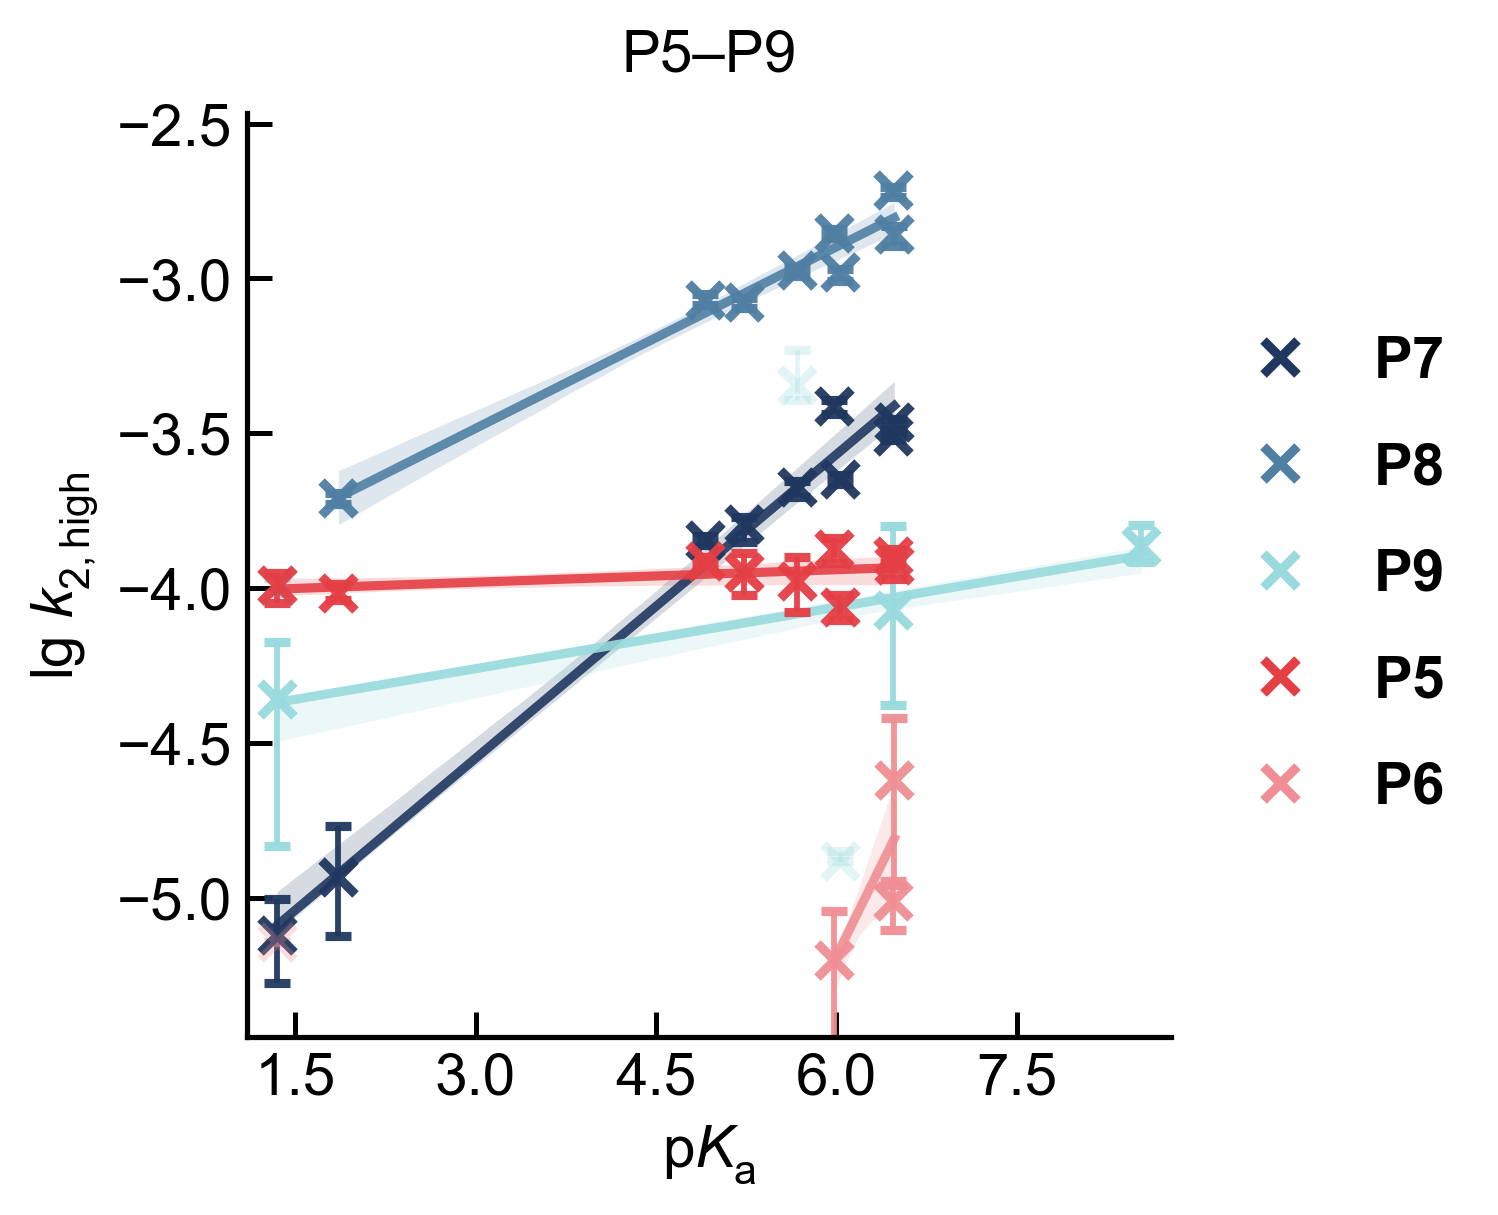

,n_points_fit,n_points_outliers,slope_beta_nuc,slope_beta_nuc_lo95,slope_beta_nuc_hi95,r2
PX,,,,,,
P7,9,0,0.327,0.299,0.346,0.983
P8,8,1,0.195,0.17,0.222,0.962
P9,3,2,0.0661,0.0568,0.0858,0.978
P5,9,0,0.0134,-0.000643,0.0234,0.185
P6,3,1,0.789,0.41,1.16,0.58


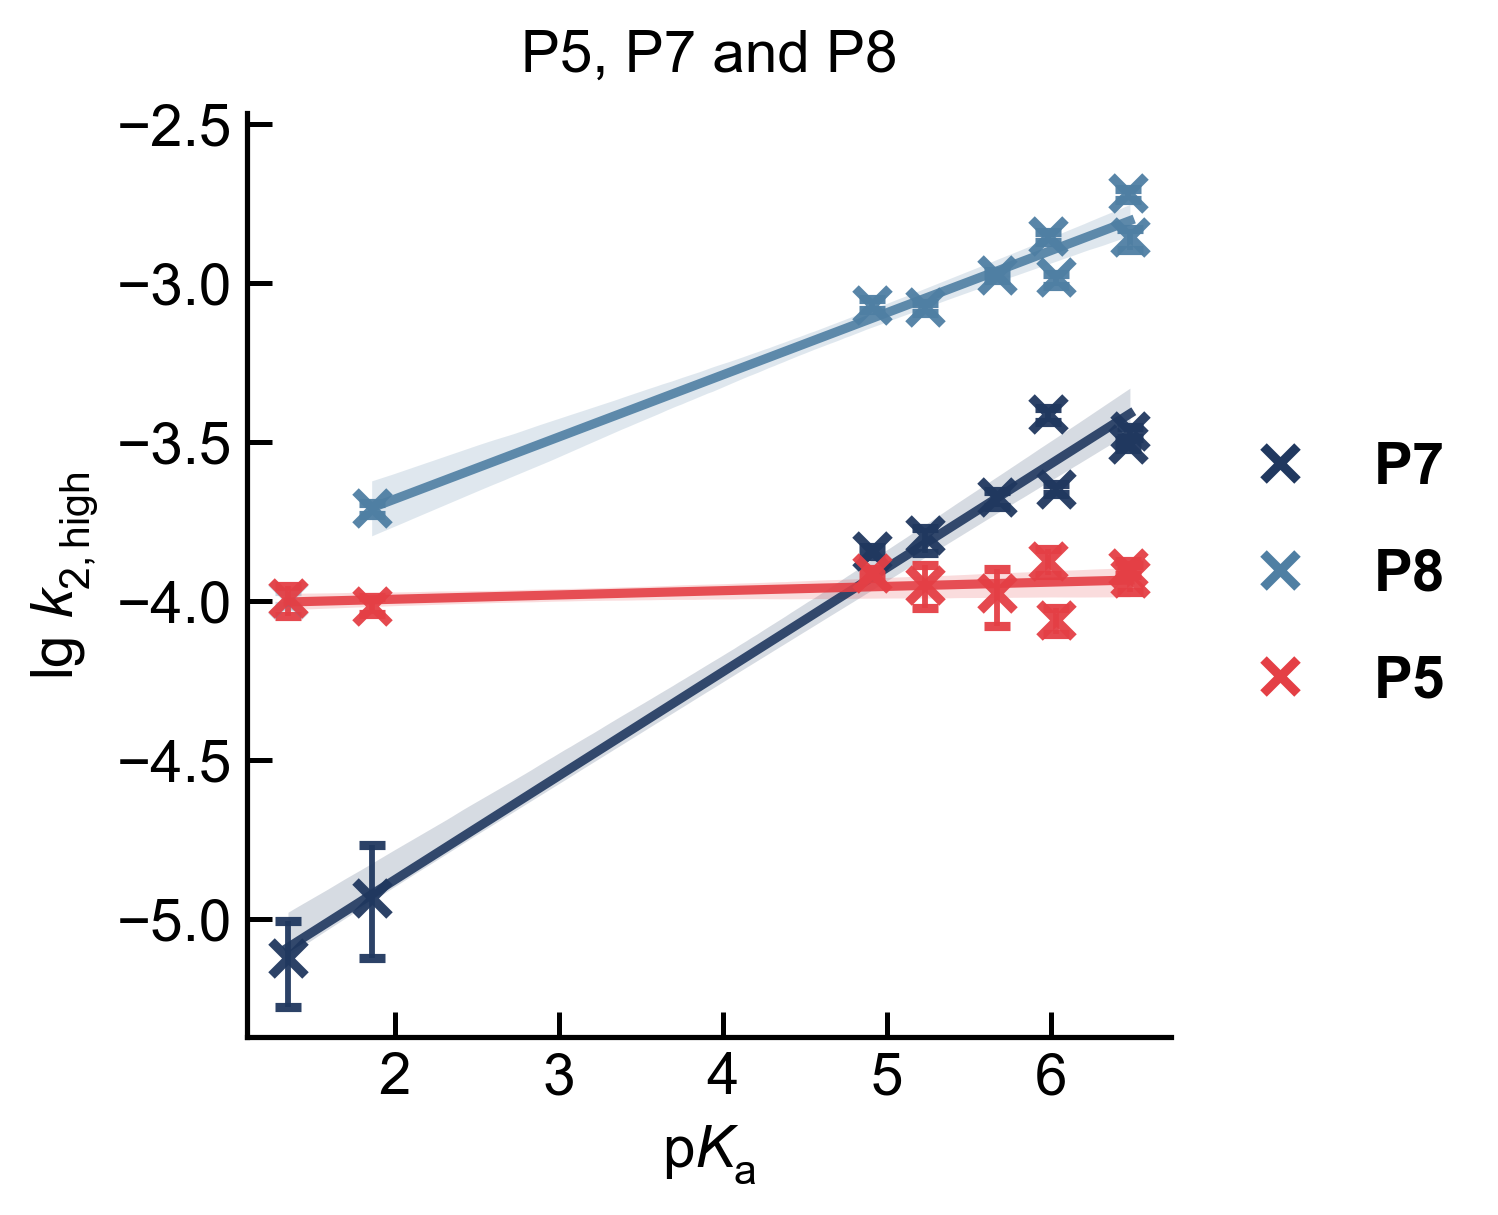

,n_points_fit,n_points_outliers,slope_beta_nuc,slope_beta_nuc_lo95,slope_beta_nuc_hi95,r2
PX,,,,,,
P7,9,0,0.327,0.301,0.346,0.983
P8,8,1,0.195,0.171,0.222,0.962
P5,9,0,0.0134,-5.92e-05,0.0232,0.185


In [4]:
"""Brønsted figures: square axes, legend to the right of the plot."""


def _error_bars(group):
    return np.vstack([
        group["lg_err_low"].where(group["has_lg_error"], 0).to_numpy(float),
        group["lg_err_high"].where(group["has_lg_error"], 0).to_numpy(float),
    ])


def _draw_points(ax, group, color):
    for subset, alpha, elinewidth in ((group[group["bronsted_inlier"]], 0.95, 1.4),
                                      (group[~group["bronsted_inlier"]], 0.28, 1.1)):
        if subset.empty:
            continue
        ax.errorbar(
            subset["nu_pKa"].to_numpy(float),
            subset["lg_k2_high"].to_numpy(float),
            yerr=_error_bars(subset),
            fmt="x", markersize=8, markeredgewidth=2.2,
            color=color, ecolor=color, elinewidth=elinewidth, capsize=3.2,
            linestyle="none", alpha=alpha,
        )


def bronsted_figure(data, pxs, filename, title=None):
    """Draw one Brønsted plot and return (figure, fit summary table)."""
    pxs = [px for px in PX_ORDER if px in pxs and not data[data["PX"].eq(px)].empty]
    subset = data[data["PX"].isin(pxs)]

    fig, ax = plt.subplots(figsize=(4, 4))
    ax.set_box_aspect(1)  # square plotting area

    rows = []
    for px in pxs:
        group = data[data["PX"].eq(px)].sort_values("nu_pKa")
        color = PX_COLORS[px]
        _draw_points(ax, group, color)

        fitted = group[group["bronsted_inlier"]]
        x = fitted["nu_pKa"].to_numpy(float)
        y = fitted["lg_k2_high"].to_numpy(float)
        slope, intercept, r2 = fit_line(x, y)
        boots = bayesian_bootstrap_line(x, y)

        if np.isfinite(slope):
            xg = np.linspace(np.nanmin(x), np.nanmax(x), 150)
            ax.plot(xg, slope * xg + intercept, color=color, linewidth=2.2, alpha=0.90)
            if len(boots):
                curves = (boots["slope_beta_nuc"].to_numpy()[:, None] * xg[None, :]
                          + boots["intercept"].to_numpy()[:, None])
                ax.fill_between(xg, np.nanpercentile(curves, 2.5, axis=0),
                                np.nanpercentile(curves, 97.5, axis=0),
                                color=color, alpha=0.18, linewidth=0)

        slope_lo, slope_hi = np.nanpercentile(boots["slope_beta_nuc"], [2.5, 97.5]) if len(boots) else (np.nan, np.nan)
        intercept_lo, intercept_hi = np.nanpercentile(boots["intercept"], [2.5, 97.5]) if len(boots) else (np.nan, np.nan)
        rows.append({
            "PX": px,
            "n_points_total": len(group),
            "n_points_fit": len(fitted),
            "n_points_outliers": int((~group["bronsted_inlier"]).sum()),
            "outlier_nucleophiles": ", ".join(group.loc[~group["bronsted_inlier"], "nu_name"].astype(str)),
            "slope_beta_nuc": slope,
            "slope_beta_nuc_lo95": slope_lo,
            "slope_beta_nuc_hi95": slope_hi,
            "intercept": intercept,
            "intercept_lo95": intercept_lo,
            "intercept_hi95": intercept_hi,
            "r2": r2,
        })

    ax.set_xlabel(LABEL_PKA)
    ax.set_ylabel(LABEL_LG_K2)
    ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.2)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.minorticks_off()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlim(subset["nu_pKa"].min() - 0.25, subset["nu_pKa"].max() + 0.25)
    ax.set_ylim(subset["lg_k2_high"].min() - 0.25, subset["lg_k2_high"].max() + 0.25)
    if title:
        ax.set_title(title, fontsize=BASE_FONT_SIZE, pad=10)

    legend = ax.legend(
        handles=[Line2D([0], [0], marker="x", linestyle="none", color=PX_COLORS[px],
                        markeredgewidth=2.2, markersize=8, label=px) for px in pxs],
        loc="center left", bbox_to_anchor=(1.03, 0.5),
        frameon=False, handletextpad=0.6, labelspacing=0.9, borderaxespad=0.0,
    )
    for text in legend.get_texts():
        text.set_fontweight("bold")

    save_figure(fig, filename)
    return fig, pd.DataFrame(rows)


BRONSTED_PANELS = {
    "P5_P9": (PX_ORDER, "P5–P9"),
    "P5_P7_P8": (["P5", "P7", "P8"], "P5, P7 and P8"),
}

fits = {}
for panel, (pxs, label) in BRONSTED_PANELS.items():
    fig, table = bronsted_figure(bronsted, pxs, f"bronsted_pyridines_{panel}.png", title=label)
    plt.show()
    fits[panel] = table
    display(table.set_index("PX")[["n_points_fit", "n_points_outliers", "slope_beta_nuc",
                                   "slope_beta_nuc_lo95", "slope_beta_nuc_hi95", "r2"]])

## 3 · Export

Plot data, fitted parameters, flagged points, reference values and excluded unconstrained values are written to `bronsted_pyridines_plot_data.xlsx`.

In [5]:
"""Write every number behind the figures to one workbook."""

PLOT_DATA_COLS = [
    "PX", "nu_id", "nu_name", "nu_pKa", "nu_pKa_reference",
    "final_k2_high", "final_k2_high_lo95", "final_k2_high_hi95",
    "lg_k2_high", "lg_k2_high_lo95", "lg_k2_high_hi95",
    "final_k2_high_method", "bronsted_inlier", "bronsted_residual",
    "bronsted_leverage", "bronsted_cooks_d", "bronsted_cooks_d_cutoff",
    "bronsted_outlier_reason",
]
plot_data = bronsted[PLOT_DATA_COLS].sort_values(["PX", "nu_pKa"]).reset_index(drop=True)

fit_table = pd.concat(
    [table.assign(panel=panel) for panel, table in fits.items()], ignore_index=True
)
fit_table = fit_table[["panel"] + [c for c in fit_table.columns if c != "panel"]]

output_xlsx = OUTPUT_DIR / "bronsted_pyridines_plot_data.xlsx"
with pd.ExcelWriter(output_xlsx, engine="openpyxl") as writer:
    plot_data.to_excel(writer, sheet_name="plot_data", index=False)
    fit_table.to_excel(writer, sheet_name="bronsted_fits", index=False)
    plot_data[~plot_data["bronsted_inlier"]].to_excel(writer, sheet_name="flagged_outliers", index=False)
    pyridine_ref.sort_values("nu_pKa").to_excel(writer, sheet_name="pyridine_reference", index=False)
    unconstrained.to_excel(writer, sheet_name="discarded_unconstrained", index=False)

    for worksheet in writer.book.worksheets:
        worksheet.freeze_panes = "A2"
        for column_cells in worksheet.columns:
            header = str(column_cells[0].value)
            worksheet.column_dimensions[column_cells[0].column_letter].width = min(max(len(header) + 2, 12), 34)
        for row in worksheet.iter_rows(min_row=2):
            for cell in row:
                if not isinstance(cell.value, (int, float)):
                    continue
                header = str(worksheet.cell(1, cell.column).value)
                if "k2" in header and "lg" not in header:
                    cell.number_format = "0.00E+00"
                elif "pKa" in header or header in {"slope_beta_nuc", "intercept", "r2"}:
                    cell.number_format = "0.000"

SAVED_FILES.append(output_xlsx)
print(f"{len(SAVED_FILES)} files written to {OUTPUT_DIR}:")
for path in SAVED_FILES:
    print(f"  {path.relative_to(OUTPUT_DIR)}")

3 files written to /Users/robertmayer/Desktop/mayerlab_local/phosphorylation_publ/section5_6_kinetics/bronsted_analysis:
  bronsted_pyridines_P5_P9.png
  bronsted_pyridines_P5_P7_P8.png
  bronsted_pyridines_plot_data.xlsx
